# HR Analytics — Week 3: Forecasting Questions
**Tools:** Python (scikit-learn, pandas, Matplotlib) · **Input:** cleaned dataset from Week 1

> The dataset is a single snapshot (no dates), so "forecasting" here means **predictive modelling**: learning the patterns in current employees and using them to predict outcomes for new/unseen employees. Every model is evaluated on held-out data (80/20 stratified split) plus 5-fold cross-validation.

| # | Question | Task |
|---|---|---|
| 1–3 | Attrition prediction, key factors, highest-risk employees | Classification |
| 4–5 | Job-satisfaction prediction and key factors | Classification |
| 6–7 | Monthly income and salary-hike prediction | Regression |
| 8–9 | Long-term retention profiles, promotion likelihood | Classification |

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, f1_score, r2_score, mean_absolute_error, precision_score, recall_score)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.25})
SEED = 42
df = pd.read_csv('week1/hr_attrition_cleaned.csv')
RESULTS = []   # (question, metric, value)
def log(q, metric, v): RESULTS.append((q, metric, round(float(v),3)))

CAT = ['business_travel','department','education_field','gender','job_role','marital_status','overtime']
def make_pre(cols, scale=False):
    num = [c for c in cols if c not in CAT]; cat = [c for c in cols if c in CAT]
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', num),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat)], verbose_feature_names_out=False)
def perm_imp(pipe, Xte, yte, scoring, n=20):
    r = permutation_importance(pipe, Xte, yte, scoring=scoring, n_repeats=n, random_state=SEED)
    return pd.Series(r.importances_mean, index=Xte.columns), pd.Series(r.importances_std, index=Xte.columns)
def barh_imp(ax, imp, std, title, color='#4c72b0', top=12):
    s = imp.sort_values().tail(top); ax.barh(s.index, s.values, xerr=std[s.index].values, color=color, alpha=.9)
    ax.set_title(title); ax.set_xlabel('Drop in score when feature is shuffled')
print(df.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/week1/hr_attrition_cleaned.csv'

## 1. Employee Attrition Prediction (Questions 1–3)

In [2]:
ID_LAB = ['employee_id','attrition','attrition_flag','overtime_flag'] + [c for c in df if c.endswith('_label') or c.endswith('_band') or c=='age_group']
F_ATT = [c for c in df if c not in ID_LAB]
X, y = df[F_ATT], df['attrition_flag']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

models = {
 'Logistic Regression': Pipeline([('p', make_pre(F_ATT, True)), ('m', LogisticRegression(class_weight='balanced', C=.3, max_iter=3000))]),
 'Random Forest':       Pipeline([('p', make_pre(F_ATT)), ('m', RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1))]),
 'Gradient Boosting':   Pipeline([('p', make_pre(F_ATT)), ('m', GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=.08, random_state=SEED))]),
}
cv_auc = {k: cross_val_score(m, Xtr, ytr, cv=skf, scoring='roc_auc').mean() for k,m in models.items()}
print({k: round(v,3) for k,v in cv_auc.items()})
best = max(cv_auc, key=cv_auc.get); print('Best by CV AUC:', best)
for m in models.values(): m.fit(Xtr, ytr)
probs = {k: m.predict_proba(Xte)[:,1] for k,m in models.items()}
for k,p in probs.items(): print(k, 'test AUC =', round(roc_auc_score(yte,p),3))

{'Logistic Regression': np.float64(0.829), 'Random Forest': np.float64(0.808), 'Gradient Boosting': np.float64(0.82)}
Best by CV AUC: Logistic Regression


Logistic Regression test AUC = 0.809
Random Forest test AUC = 0.794
Gradient Boosting test AUC = 0.821


threshold=0.69
              precision    recall  f1-score   support

      Stayed       0.90      0.92      0.91       247
        Left       0.51      0.45      0.48        47

    accuracy                           0.84       294
   macro avg       0.70      0.68      0.69       294
weighted avg       0.84      0.84      0.84       294



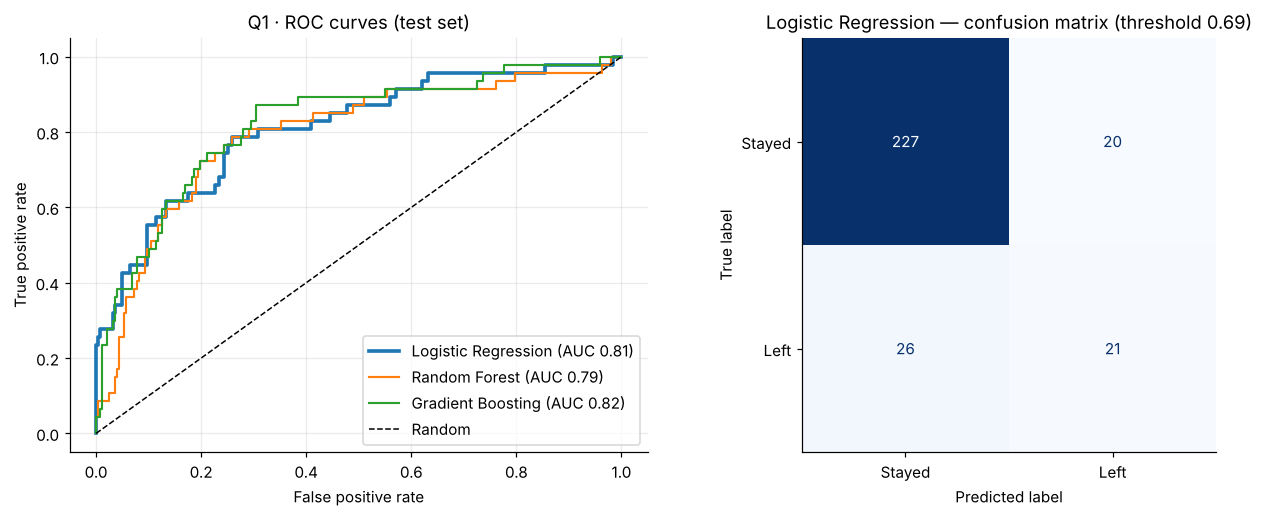

In [3]:
# Decision threshold: choose the one maximising F1 on out-of-fold training predictions (not on test)
oof = cross_val_predict(models[best], Xtr, ytr, cv=skf, method='predict_proba')[:,1]
ths = np.linspace(.05,.8,76); f1s = [f1_score(ytr, oof>=t) for t in ths]; thr = ths[int(np.argmax(f1s))]
pte = probs[best]; pred = (pte>=thr).astype(int)
print(f'threshold={thr:.2f}')
print(classification_report(yte, pred, target_names=['Stayed','Left']))
auc_best = roc_auc_score(yte, pte)
log('Q1','Test ROC-AUC',auc_best); log('Q1','Recall (Left)',recall_score(yte,pred)); log('Q1','Precision (Left)',precision_score(yte,pred))

fig, ax = plt.subplots(1,2, figsize=(12,4.8))
for k,p in probs.items():
    f,t,_ = roc_curve(yte,p); ax[0].plot(f,t,lw=2.4 if k==best else 1.4, label=f'{k} (AUC {roc_auc_score(yte,p):.2f})')
ax[0].plot([0,1],[0,1],'k--',lw=1,label='Random'); ax[0].set(xlabel='False positive rate', ylabel='True positive rate', title='Q1 · ROC curves (test set)'); ax[0].legend(loc='lower right')
ConfusionMatrixDisplay(confusion_matrix(yte,pred), display_labels=['Stayed','Left']).plot(ax=ax[1], cmap='Blues', colorbar=False); ax[1].grid(False)
ax[1].set_title(f'{best} — confusion matrix (threshold {thr:.2f})')
plt.tight_layout(); plt.savefig('figures/q1_attrition_model.png', dpi=140); plt.show()

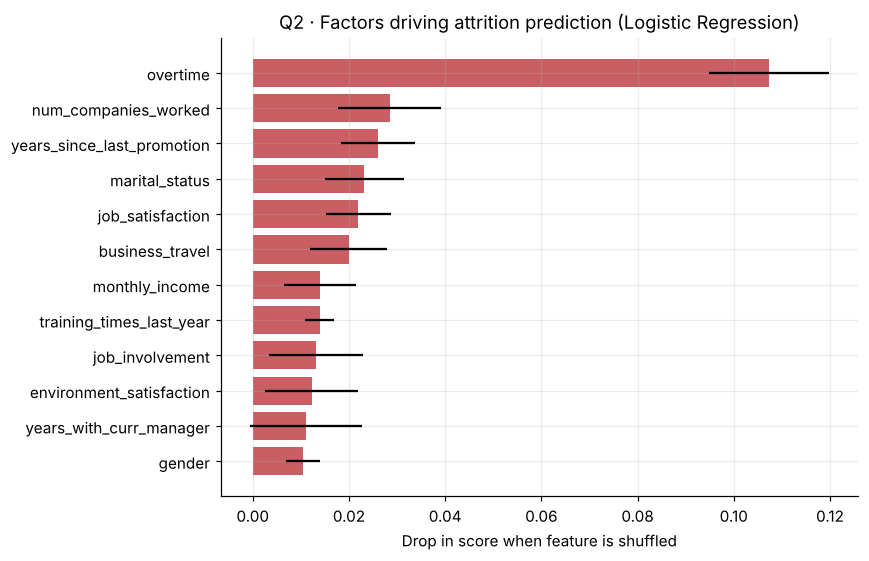

overtime                      0.107
num_companies_worked          0.028
years_since_last_promotion    0.026
marital_status                0.023
job_satisfaction              0.022
business_travel               0.020
monthly_income                0.014
training_times_last_year      0.014
dtype: float64


In [4]:
# Q2 — permutation importance on the held-out test set (model-agnostic, works on original columns)
imp, sd = perm_imp(models[best], Xte, yte, 'roc_auc')
fig, ax = plt.subplots(figsize=(8,5.2)); barh_imp(ax, imp, sd, f'Q2 · Factors driving attrition prediction ({best})', '#c44e52', 12)
plt.tight_layout(); plt.savefig('figures/q2_attrition_factors.png', dpi=140); plt.show()
print(imp.sort_values(ascending=False).head(8).round(3))

['overtime', 'num_companies_worked', 'years_since_last_promotion', 'marital_status', 'job_satisfaction', 'business_travel']


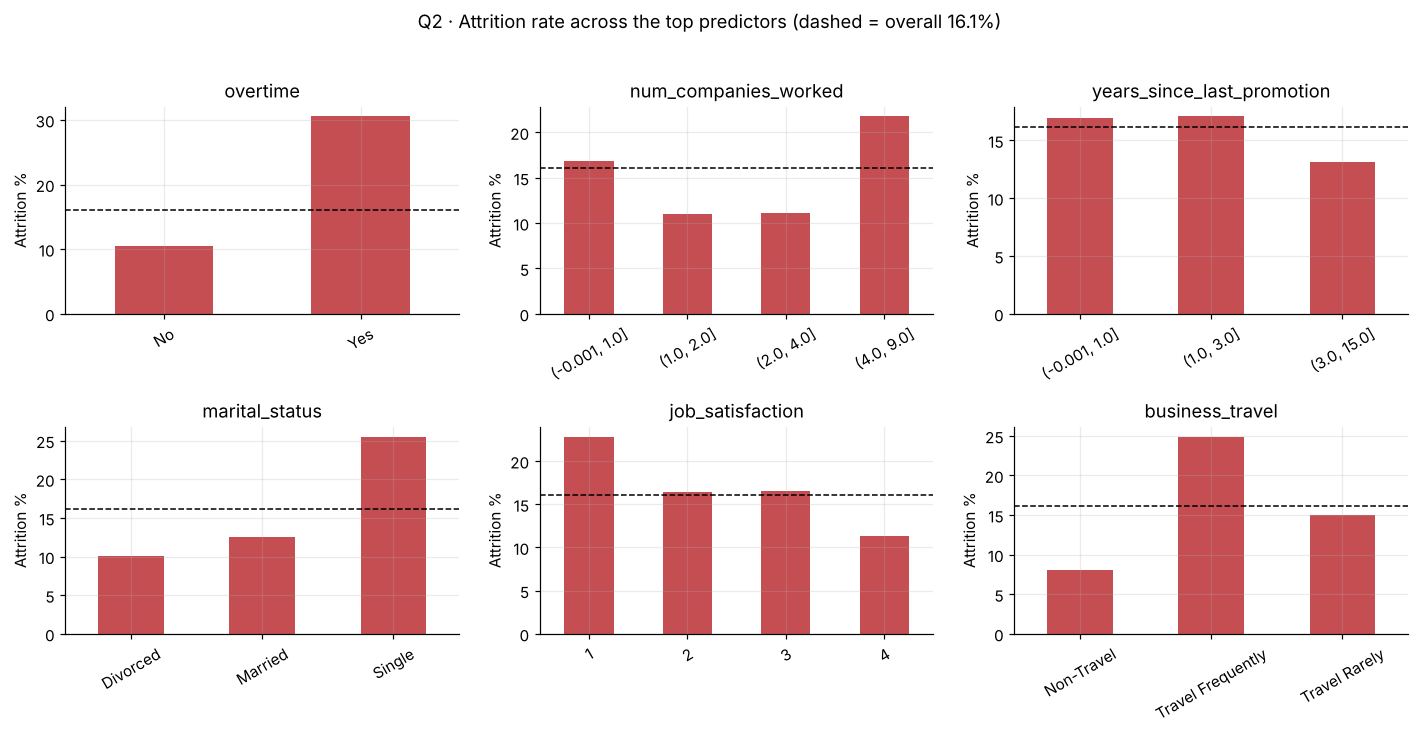

In [5]:
# Direction of the top factors (attrition rate per group) — helps interpret *how* they matter
top = imp.sort_values(ascending=False).index[:6].tolist(); print(top)
fig, axes = plt.subplots(2,3, figsize=(13,6.5))
for ax,c in zip(axes.ravel(), top):
    s = df[c]
    if c not in CAT and s.nunique()>8: s = pd.qcut(s, 4, duplicates='drop')
    r = df.groupby(s, observed=True)['attrition_flag'].mean()*100
    r.plot.bar(ax=ax, color='#c44e52', rot=30); ax.axhline(df.attrition_flag.mean()*100, color='k', ls='--', lw=1); ax.set(title=c, xlabel='', ylabel='Attrition %')
plt.suptitle('Q2 · Attrition rate across the top predictors (dashed = overall 16.1%)', y=1.02); plt.tight_layout()
plt.savefig('figures/q2b_attrition_rate_by_top_factors.png', dpi=140, bbox_inches='tight'); plt.show()

Base attrition: 16.1% | actually left among top-50 scored: 88.0%


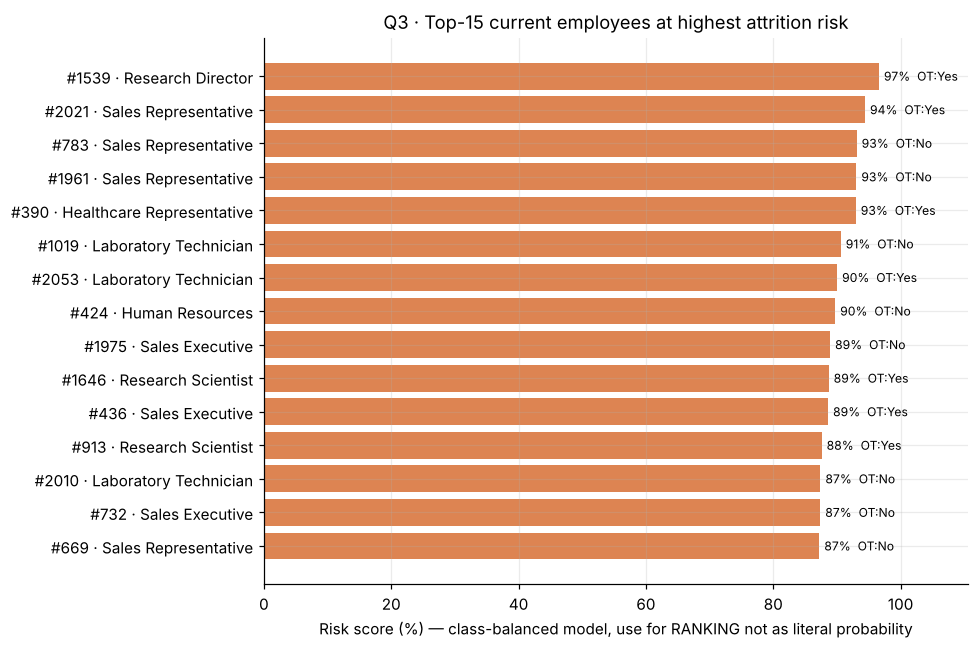

                employees  actual_attrition
prob_leave                                 
Low <20%              549             0.033
Medium 20-40%         331             0.085
High 40-60%           249             0.165
Very high >60%        341             0.440


In [6]:
# Q3 — every employee scored with an out-of-fold probability (the model never saw that employee when scoring)
oof_all = cross_val_predict(models[best], X, y, cv=skf, method='predict_proba')[:,1]
risk = df[['employee_id','job_role','department','overtime','monthly_income','age','attrition']].assign(prob_leave=oof_all).sort_values('prob_leave', ascending=False)
risk.to_csv('attrition_risk_scores.csv', index=False)
cur = risk[risk.attrition=='No']      # current employees still at risk
base = y.mean(); top50 = risk.head(50).attrition.eq('Yes').mean()
print(f'Base attrition: {base:.1%} | actually left among top-50 scored: {top50:.1%}')
log('Q3','Attrition rate in top-50 risk',top50); log('Q3','Base attrition rate',base)

t = cur.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9,6))
ax.barh([f'#{i} · {r}' for i,r in zip(t.employee_id, t.job_role)], t.prob_leave*100, color='#dd8452')
for i,(p,o) in enumerate(zip(t.prob_leave, t.overtime)): ax.text(p*100+.8, i, f'{p:.0%}  OT:{o}', va='center', fontsize=8)
ax.set(xlabel='Risk score (%) — class-balanced model, use for RANKING not as literal probability', title='Q3 · Top-15 current employees at highest attrition risk', xlim=(0, t.prob_leave.max()*100+14))
plt.tight_layout(); plt.savefig('figures/q3_highest_risk_employees.png', dpi=140); plt.show()

# Risk tiers over all employees
tier = pd.cut(risk.prob_leave, [0,.2,.4,.6,1], labels=['Low <20%','Medium 20-40%','High 40-60%','Very high >60%'])
print(risk.groupby(tier, observed=True).agg(employees=('employee_id','size'), actual_attrition=('attrition', lambda s:(s=='Yes').mean())).round(3))

## 2. Employee Satisfaction Prediction (Questions 4–5)

                         accuracy  macro_F1
Majority-class baseline     0.313       NaN
Logistic Regression         0.276     0.197
Random Forest               0.218     0.208


Binary (satisfied vs not) test AUC = 0.452 | 5-fold CV AUC = 0.464 ± 0.034


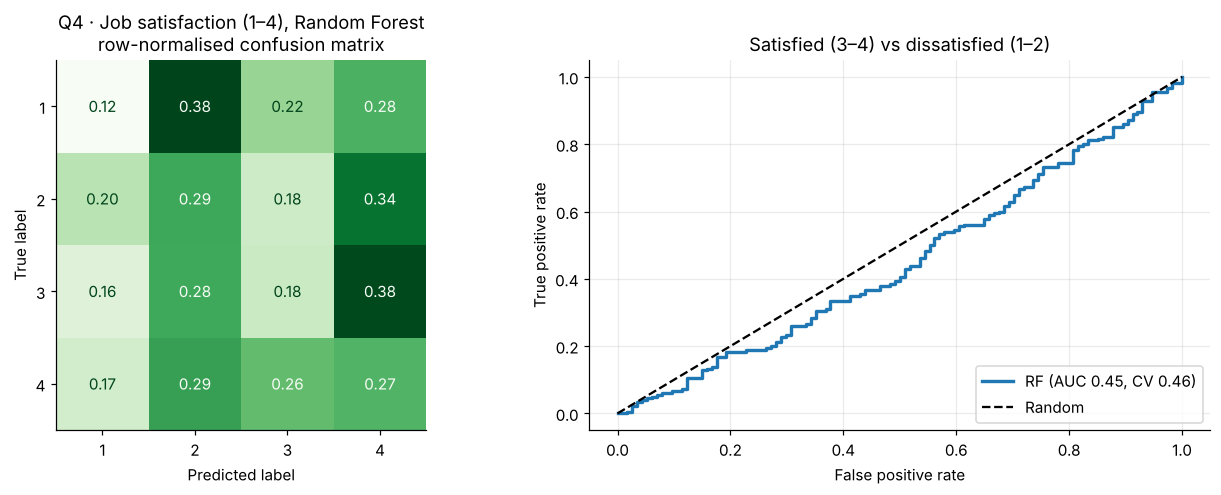

In [7]:
F_SAT = ['environment_satisfaction','work_life_balance','job_role','department','monthly_income','job_level','overtime','age','years_at_company',
         'job_involvement','relationship_satisfaction','business_travel','distance_from_home','stock_option_level','marital_status','gender','performance_rating','training_times_last_year']
X, y = df[F_SAT], df['job_satisfaction']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
rf = Pipeline([('p', make_pre(F_SAT)), ('m', RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1))]).fit(Xtr,ytr)
lr = Pipeline([('p', make_pre(F_SAT, True)), ('m', LogisticRegression(max_iter=3000, C=.3))]).fit(Xtr,ytr)
base_acc = (yte==ytr.mode()[0]).mean()
res = {'Majority-class baseline': (base_acc, np.nan), 'Logistic Regression': (accuracy_score(yte, lr.predict(Xte)), f1_score(yte, lr.predict(Xte), average='macro')),
       'Random Forest': (accuracy_score(yte, rf.predict(Xte)), f1_score(yte, rf.predict(Xte), average='macro'))}
print(pd.DataFrame(res, index=['accuracy','macro_F1']).T.round(3))

# Binary version: satisfied (3-4) vs dissatisfied (1-2)
yb = (df['job_satisfaction']>=3).astype(int); Xtr_b, Xte_b, ytr_b, yte_b = train_test_split(X, yb, test_size=.2, stratify=yb, random_state=SEED)
rfb = Pipeline([('p', make_pre(F_SAT)), ('m', RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1))]).fit(Xtr_b,ytr_b)
auc_b = roc_auc_score(yte_b, rfb.predict_proba(Xte_b)[:,1])
cv_b = cross_val_score(Pipeline([('p', make_pre(F_SAT)), ('m', RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1))]), X, yb, cv=StratifiedKFold(5,shuffle=True,random_state=SEED), scoring='roc_auc')
print(f'Binary (satisfied vs not) test AUC = {auc_b:.3f} | 5-fold CV AUC = {cv_b.mean():.3f} ± {cv_b.std():.3f}')
log('Q4','4-class accuracy (RF)',res['Random Forest'][0]); log('Q4','4-class baseline accuracy',base_acc); log('Q4','Binary satisfied ROC-AUC (CV)',cv_b.mean())

fig, ax = plt.subplots(1,2, figsize=(12,4.6))
ConfusionMatrixDisplay.from_predictions(yte, rf.predict(Xte), normalize='true', cmap='Greens', ax=ax[0], colorbar=False, values_format='.2f'); ax[0].grid(False)
ax[0].set_title('Q4 · Job satisfaction (1–4), Random Forest\nrow-normalised confusion matrix')
f,t,_ = roc_curve(yte_b, rfb.predict_proba(Xte_b)[:,1]); ax[1].plot(f,t,lw=2.2,label=f'RF (AUC {auc_b:.2f}, CV {cv_b.mean():.2f})'); ax[1].plot([0,1],[0,1],'k--',label='Random')
ax[1].set(title='Satisfied (3–4) vs dissatisfied (1–2)', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend(loc='lower right')
plt.tight_layout(); plt.savefig('figures/q4_satisfaction_model.png', dpi=140); plt.show()

                   factor  p_value  spearman_rho
               department    0.202           NaN
        work_life_balance    0.254        -0.030
                 overtime    0.297           NaN
                   gender    0.467           NaN
          business_travel    0.516           NaN
relationship_satisfaction    0.574        -0.015
       distance_from_home    0.616        -0.013
       stock_option_level    0.624         0.013
         years_at_company    0.638         0.012
          job_involvement    0.642        -0.012
 training_times_last_year    0.655        -0.012
                 job_role    0.783           NaN
       performance_rating    0.789         0.007
           marital_status    0.828           NaN
                      age    0.843        -0.005
           monthly_income    0.852         0.005
 environment_satisfaction    0.909        -0.003
                job_level    0.974        -0.001
Factors with p<0.05: 0 of 18 (expected by chance alone ~ 0.9 )


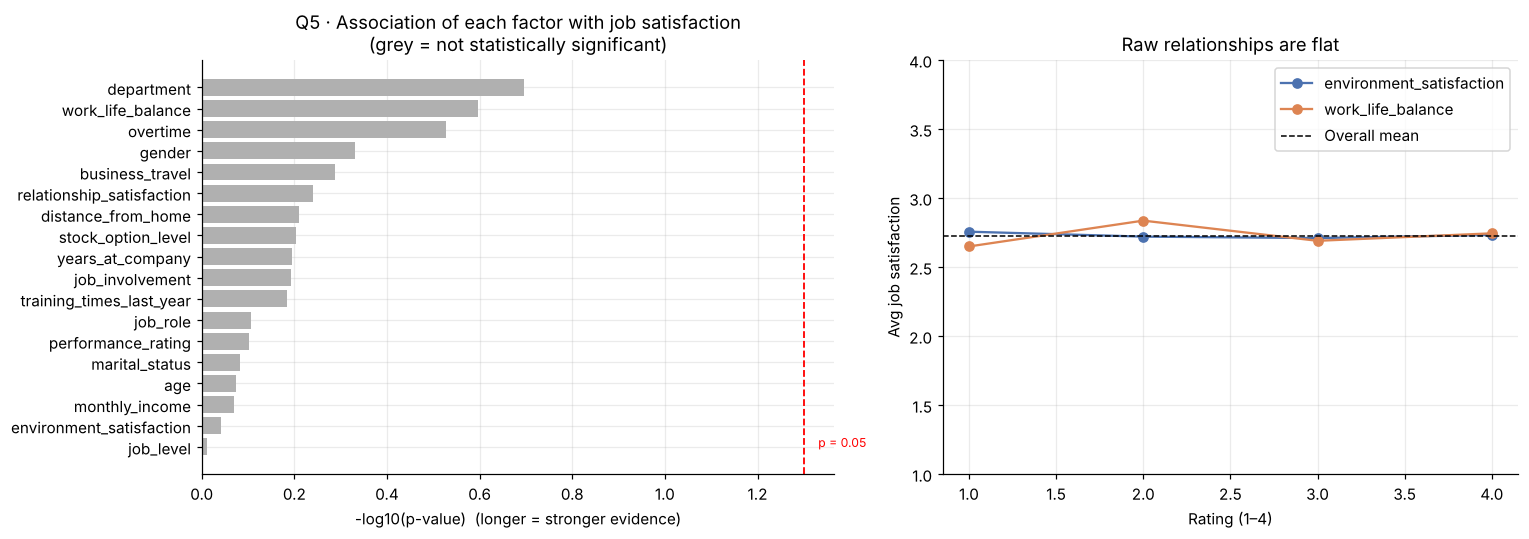

In [8]:
# Q5 — The model above cannot beat chance (AUC<0.5), so model-based importances would be noise. Instead test each factor
# directly against job_satisfaction: Spearman correlation (numeric) / chi-square (categorical). Small p (< 0.05) = real association.
from scipy import stats
rows=[]
for c in F_SAT:
    if c in CAT:
        p = stats.chi2_contingency(pd.crosstab(df[c], df['job_satisfaction']))[1]; eff = np.nan
    else:
        rho,p = stats.spearmanr(df[c], df['job_satisfaction']); eff = rho
    rows.append((c, p, eff))
assoc = pd.DataFrame(rows, columns=['factor','p_value','spearman_rho']).sort_values('p_value'); print(assoc.round(3).to_string(index=False))
n_sig = (assoc.p_value<.05).sum(); print('Factors with p<0.05:', n_sig, 'of', len(assoc), '(expected by chance alone ~', round(len(assoc)*.05,1), ')')
log('Q5','Factors with p<0.05',n_sig)

fig, ax = plt.subplots(1,2, figsize=(14,5), gridspec_kw={'width_ratios':[1.1,1]})
a = assoc.sort_values('p_value', ascending=False); ax[0].barh(a.factor, -np.log10(a.p_value), color=np.where(a.p_value<.05,'#55a868','#b0b0b0'))
ax[0].axvline(-np.log10(.05), color='r', ls='--', lw=1.2); ax[0].text(-np.log10(.05)+.03, 0, 'p = 0.05', color='r', fontsize=8)
ax[0].set(xlabel='-log10(p-value)  (longer = stronger evidence)', title='Q5 · Association of each factor with job satisfaction\n(grey = not statistically significant)')
for c,col in [('environment_satisfaction','#4c72b0'),('work_life_balance','#dd8452')]:
    ax[1].plot(df.groupby(c).job_satisfaction.mean(), marker='o', color=col, label=c)
ax[1].axhline(df.job_satisfaction.mean(), color='k', ls='--', lw=1, label='Overall mean'); ax[1].set(ylim=(1,4), xlabel='Rating (1–4)', ylabel='Avg job satisfaction', title='Raw relationships are flat'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/q5_satisfaction_factors.png', dpi=140); plt.show()

## 3. Salary & Compensation Prediction (Questions 6–7)

{'Linear Regression': np.float64(0.942), 'Random Forest': np.float64(0.949), 'Gradient Boosting': np.float64(0.953)}


Gradient Boosting: test R²=0.943  MAE=$813  median abs % error=11.3%


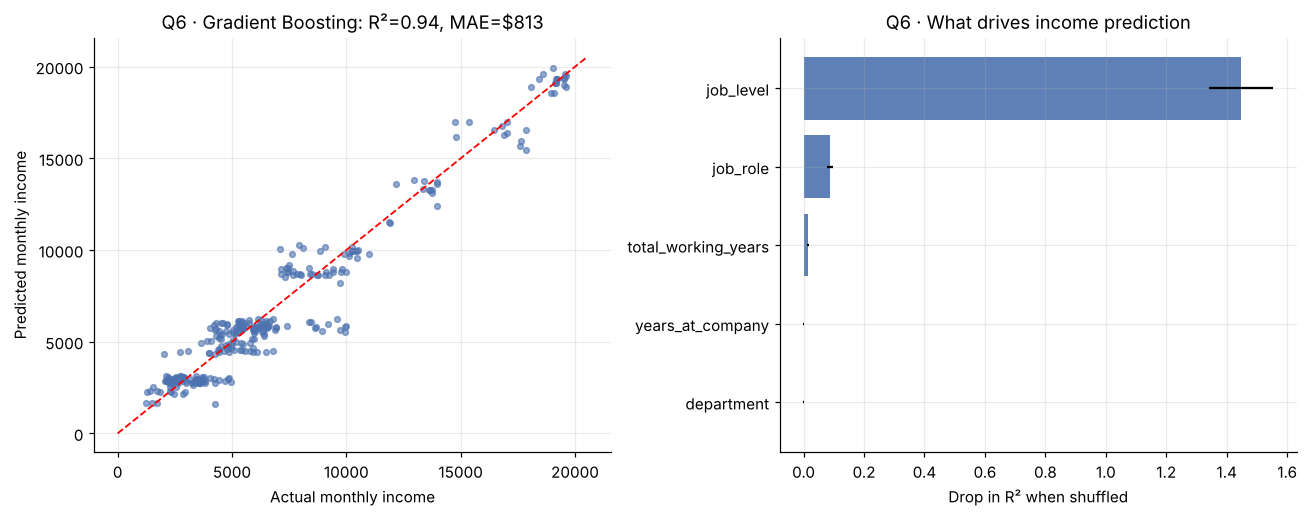

In [9]:
F_INC = ['job_role','job_level','department','total_working_years','years_at_company']
X, y = df[F_INC], df['monthly_income']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, random_state=SEED)
kf = KFold(5, shuffle=True, random_state=SEED)
reg = {'Linear Regression': Pipeline([('p', make_pre(F_INC, True)), ('m', LinearRegression())]),
       'Random Forest':     Pipeline([('p', make_pre(F_INC)), ('m', RandomForestRegressor(400, min_samples_leaf=3, random_state=SEED, n_jobs=-1))]),
       'Gradient Boosting': Pipeline([('p', make_pre(F_INC)), ('m', GradientBoostingRegressor(n_estimators=250, max_depth=3, learning_rate=.05, random_state=SEED))])}
cvr = {k: cross_val_score(m, Xtr, ytr, cv=kf, scoring='r2').mean() for k,m in reg.items()}; print({k: round(v,3) for k,v in cvr.items()})
bestr = max(cvr, key=cvr.get); mdl = reg[bestr].fit(Xtr,ytr); pr = mdl.predict(Xte)
r2, mae = r2_score(yte,pr), mean_absolute_error(yte,pr); mape = (abs(yte-pr)/yte).median()
print(f'{bestr}: test R²={r2:.3f}  MAE=${mae:,.0f}  median abs % error={mape:.1%}')
log('Q6','Test R²',r2); log('Q6','MAE ($)',mae); log('Q6','Median abs % error',mape)

fig, ax = plt.subplots(1,2, figsize=(12,4.8))
ax[0].scatter(yte, pr, s=14, alpha=.6, color='#4c72b0'); lim=[0, max(yte.max(), pr.max())*1.03]; ax[0].plot(lim,lim,'r--',lw=1.2)
ax[0].set(xlabel='Actual monthly income', ylabel='Predicted monthly income', title=f'Q6 · {bestr}: R²={r2:.2f}, MAE=${mae:,.0f}')
imp, sd = perm_imp(mdl, Xte, yte, 'r2'); barh_imp(ax[1], imp, sd, 'Q6 · What drives income prediction', '#4c72b0', 8); ax[1].set_xlabel('Drop in R² when shuffled')
plt.tight_layout(); plt.savefig('figures/q6_income_prediction.png', dpi=140); plt.show()

CV R²  linear=0.597  forest=0.595
MAE: mean-only baseline=3.06 pts | linear model=1.88 pts
Corr(hike, performance)=0.77  Corr(hike, job_level)=-0.03


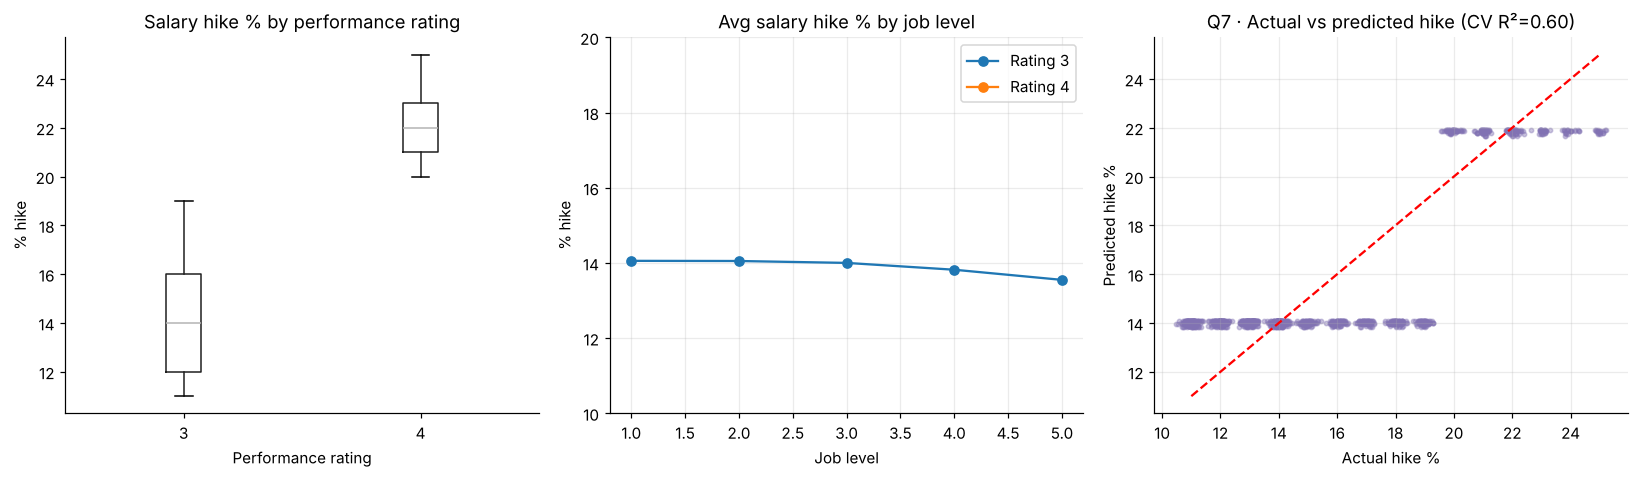

In [10]:
# Q7 — how accurately can salary INCREASE (percent_salary_hike) be estimated from performance rating and job level?
F_HIKE = ['performance_rating','job_level']; X, y = df[F_HIKE], df['percent_salary_hike']
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=kf, scoring='r2'); cv_rf = cross_val_score(RandomForestRegressor(300, min_samples_leaf=20, random_state=SEED), X, y, cv=kf, scoring='r2')
lin = LinearRegression().fit(X,y); mae_base = mean_absolute_error(y, np.full(len(y), y.mean())); mae_lin = mean_absolute_error(y, lin.predict(X))
print(f'CV R²  linear={cv_r2.mean():.3f}  forest={cv_rf.mean():.3f}')
print(f'MAE: mean-only baseline={mae_base:.2f} pts | linear model={mae_lin:.2f} pts')
print('Corr(hike, performance)=%.2f  Corr(hike, job_level)=%.2f' % (df.percent_salary_hike.corr(df.performance_rating), df.percent_salary_hike.corr(df.job_level)))
log('Q7','CV R² (linear)',cv_r2.mean()); log('Q7','MAE baseline (pts)',mae_base); log('Q7','MAE model (pts)',mae_lin)

fig, ax = plt.subplots(1,3, figsize=(15,4.6))
df.boxplot(column='percent_salary_hike', by='performance_rating', ax=ax[0], grid=False); ax[0].set(title='Salary hike % by performance rating', xlabel='Performance rating', ylabel='% hike'); ax[0].get_figure().suptitle('')
for r,g in df.groupby('performance_rating'): ax[1].plot(g.groupby('job_level').percent_salary_hike.mean(), marker='o', label=f'Rating {r}')
ax[1].set(title='Avg salary hike % by job level', xlabel='Job level', ylabel='% hike', ylim=(10,20)); ax[1].legend()
ax[2].scatter(y + np.random.default_rng(1).normal(0,.15,len(y)), lin.predict(X), s=8, alpha=.4, color='#8172b3'); ax[2].plot([11,25],[11,25],'r--')
ax[2].set(title=f'Q7 · Actual vs predicted hike (CV R²={cv_r2.mean():.2f})', xlabel='Actual hike %', ylabel='Predicted hike %')
plt.tight_layout(); plt.savefig('figures/q7_salary_hike_prediction.png', dpi=140); plt.show()

## 4. Employee Retention & Career Development (Questions 8–9)

Long-term share: 0.249


Test AUC=0.847 | CV AUC=0.841


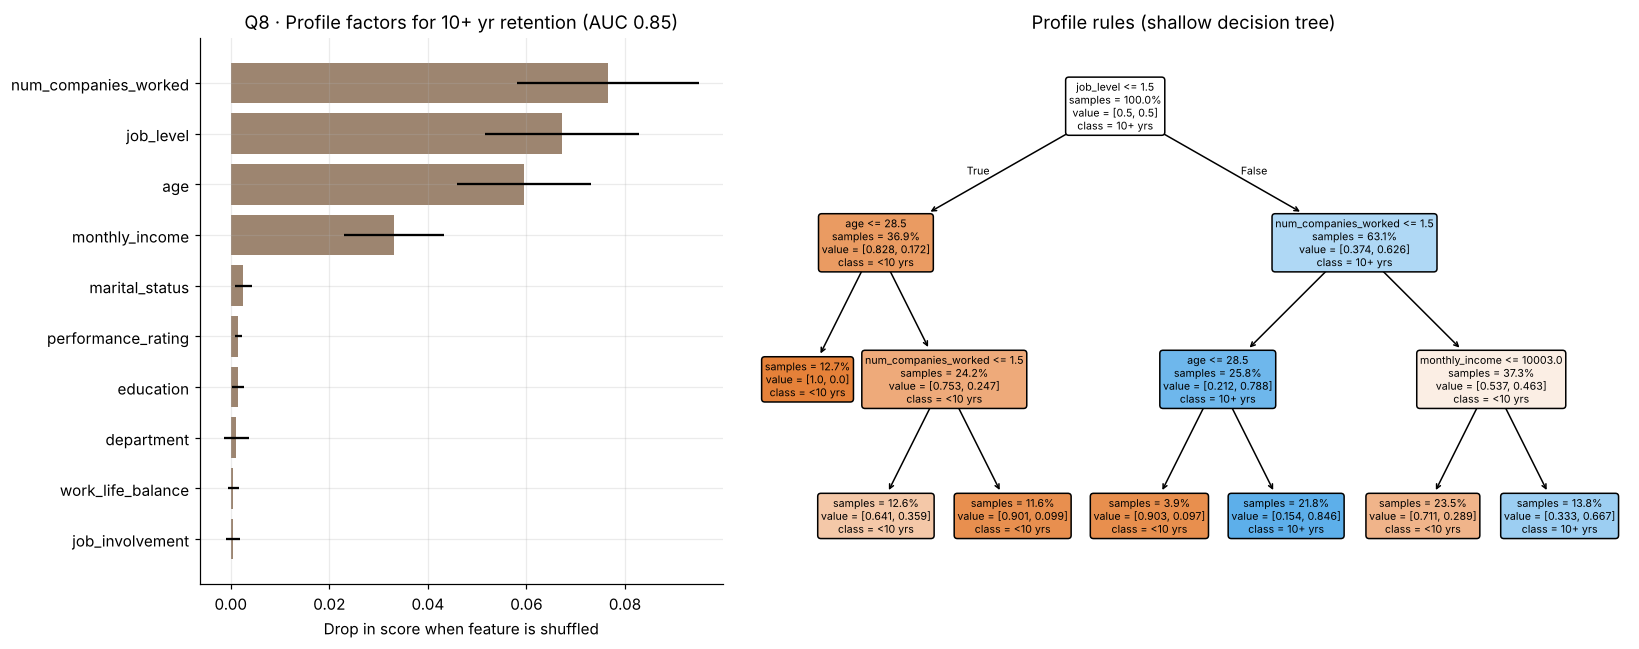

{1: 0.06, 2: 0.25, 3: 0.45, 4: 0.58, 5: 0.58}


In [11]:
# Q8 — "long-term retention" = 10+ years at the company. Tenure-derived columns (years_*, total_working_years) are excluded so the model learns PROFILES, not the definition.
df['long_term'] = (df['years_at_company']>=10).astype(int); print('Long-term share:', round(df.long_term.mean(),3))
F_RET = ['age','gender','marital_status','education','education_field','department','job_role','job_level','monthly_income','num_companies_worked','overtime',
         'business_travel','distance_from_home','stock_option_level','job_satisfaction','environment_satisfaction','work_life_balance','job_involvement','performance_rating','training_times_last_year']
X, y = df[F_RET], df['long_term']; Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
rfr = Pipeline([('p', make_pre(F_RET)), ('m', RandomForestClassifier(400, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1))]).fit(Xtr,ytr)
auc8 = roc_auc_score(yte, rfr.predict_proba(Xte)[:,1]); cv8 = cross_val_score(rfr, X, y, cv=StratifiedKFold(5,shuffle=True,random_state=SEED), scoring='roc_auc')
print(f'Test AUC={auc8:.3f} | CV AUC={cv8.mean():.3f}'); log('Q8','Test ROC-AUC',auc8); log('Q8','CV ROC-AUC',cv8.mean())

imp, sd = perm_imp(rfr, Xte, yte, 'roc_auc')
fig, ax = plt.subplots(1,2, figsize=(15,6), gridspec_kw={'width_ratios':[1,1.7]})
barh_imp(ax[0], imp, sd, f'Q8 · Profile factors for 10+ yr retention (AUC {auc8:.2f})', '#937860', 10)
pre = make_pre(F_RET); Xt = pre.fit_transform(X); names = pre.get_feature_names_out()
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, class_weight='balanced', random_state=SEED).fit(Xt, y)
plot_tree(tree, feature_names=names, class_names=['<10 yrs','10+ yrs'], filled=True, rounded=True, fontsize=7, ax=ax[1], impurity=False, proportion=True)
ax[1].set_title('Profile rules (shallow decision tree)'); ax[1].grid(False)
plt.tight_layout(); plt.savefig('figures/q8_longterm_retention_profiles.png', dpi=140); plt.show()
print(df.groupby('job_level').long_term.mean().round(2).to_dict())

Promoted in last year: 0.395


Test AUC=0.763 | CV AUC=0.766 ± 0.029


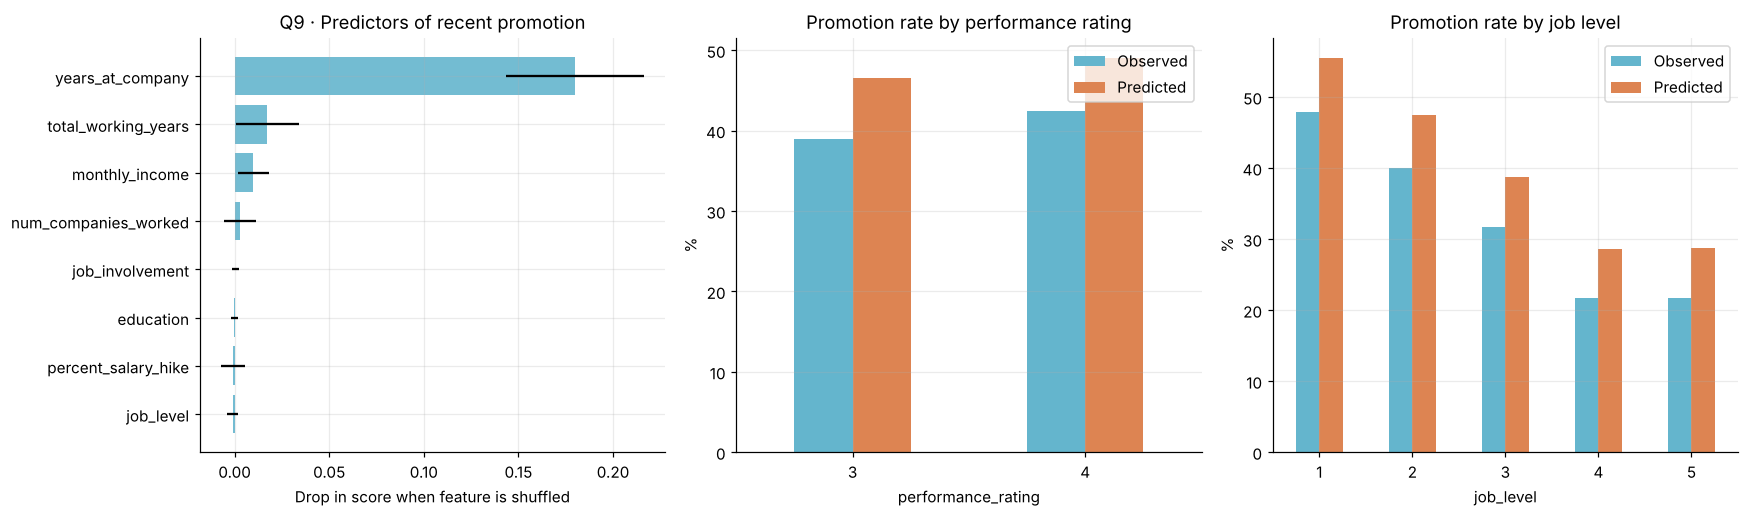

In [12]:
# Q9 — promotion likelihood. The dataset has no promotion flag, so we use a proxy: promoted in the last 12 months (years_since_last_promotion == 0).
# years_in_current_role / years_with_curr_manager are excluded: they reset on promotion, which would leak the answer.
df['promoted_recently'] = (df['years_since_last_promotion']==0).astype(int); print('Promoted in last year:', round(df.promoted_recently.mean(),3))
F_PRO = ['performance_rating','job_level','total_working_years','years_at_company','num_companies_worked','training_times_last_year','monthly_income',
         'percent_salary_hike','job_involvement','education','age','department','job_role','overtime']
X, y = df[F_PRO], df['promoted_recently']; Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
mk = lambda: Pipeline([('p', make_pre(F_PRO)), ('m', RandomForestClassifier(400, min_samples_leaf=10, class_weight='balanced', random_state=SEED, n_jobs=-1))])
pro = mk().fit(Xtr,ytr); auc9 = roc_auc_score(yte, pro.predict_proba(Xte)[:,1]); cv9 = cross_val_score(mk(), X, y, cv=StratifiedKFold(5,shuffle=True,random_state=SEED), scoring='roc_auc')
print(f'Test AUC={auc9:.3f} | CV AUC={cv9.mean():.3f} ± {cv9.std():.3f}'); log('Q9','Test ROC-AUC',auc9); log('Q9','CV ROC-AUC',cv9.mean())

oof9 = cross_val_predict(mk(), X, y, cv=StratifiedKFold(5,shuffle=True,random_state=SEED), method='predict_proba')[:,1]; df['p_promo']=oof9
imp, sd = perm_imp(pro, Xte, yte, 'roc_auc')
fig, ax = plt.subplots(1,3, figsize=(16,4.8))
barh_imp(ax[0], imp, sd, 'Q9 · Predictors of recent promotion', '#64b5cd', 8)
g = df.groupby('performance_rating')[['promoted_recently','p_promo']].mean()*100; g.plot.bar(ax=ax[1], rot=0, color=['#64b5cd','#dd8452']); ax[1].set(title='Promotion rate by performance rating', ylabel='%'); ax[1].legend(['Observed','Predicted'])
g = df.groupby('job_level')[['promoted_recently','p_promo']].mean()*100; g.plot.bar(ax=ax[2], rot=0, color=['#64b5cd','#dd8452']); ax[2].set(title='Promotion rate by job level', ylabel='%'); ax[2].legend(['Observed','Predicted'])
plt.tight_layout(); plt.savefig('figures/q9_promotion_likelihood.png', dpi=140); plt.show()

## 5. Results summary

In [13]:
summary = pd.DataFrame(RESULTS, columns=['question','metric','value']); summary.to_csv('results_summary.csv', index=False); summary

,question,metric,value
0,Q1,Test ROC-AUC,0.809
1,Q1,Recall (Left),0.447
2,Q1,Precision (Left),0.512
3,Q3,Attrition rate in top-50 risk,0.880
4,Q3,Base attrition rate,0.161
5,Q4,4-class accuracy (RF),0.218
6,Q4,4-class baseline accuracy,0.313
7,Q4,Binary satisfied ROC-AUC (CV),0.464
8,Q5,Factors with p<0.05,0.000
9,Q6,Test R²,0.943
